# KGCP: conformal prediction for knowledge graph embeddings

A knowledge graph embedding (KGE) model answers a query such as *(antibiotic, treats, ?)* by scoring every entity in the graph. The top-ranked entity is often wrong, and the scores do not say how far down the ranking the true answer may be.

**KGCP** turns these scores into an **answer set** with a coverage guarantee: for a chosen error level $\alpha$, the set contains the true answer with probability at least $1 - \alpha$ (90% for $\alpha = 0.1$). The guarantee holds for any trained model, as long as the calibration and test queries are exchangeable, e.g. a random split of the same query set.

KGCP uses split conformal prediction:

1. **Score** every candidate answer of a query with a nonconformity score computed from the model's logits (lower = more plausible).
2. **Calibrate** on held-out queries with known answers: the threshold is a quantile of their true answers' scores.
3. **Predict** for a new query the set of candidates scoring at most the threshold.
4. **Evaluate** coverage and set size, overall and per relation.

| Step | KGCP |
|---|---|
| Data | `KG`, `Queries`, `KnownAnswers` |
| Model | `LibKGE`, or any `[queries, entities]` logits |
| Score | `nonconformity` with `Neg`, `MinMax`, `Softmax`, `APS`, `RAPS`, `Rank` |
| Calibrate, predict | `SplitConformal` (marginal), `MondrianConformal` per group of queries (`by_relation`, `by_direction`, `MergedRelations`), `CondKGCP` |
| Evaluate | `evaluate` |

In [1]:
import kgcp

print(kgcp.__doc__)
print(", ".join(kgcp.__all__))

Conformal prediction of answer sets for knowledge graph embeddings.
APS, CondKGCP, HEAD, KG, KGEModel, KnownAnswers, LibKGE, MergedRelations, MinMax, MondrianConformal, Neg, PredictionSets, Queries, RAPS, Rank, RelationGroups, Scores, Softmax, SplitConformal, TAIL, by_direction, by_relation, conformal_quantile, evaluate, marginal, nonconformity


## Empirical coverage

Does the guarantee hold for trained models? We set $\alpha = 0.1$, a target coverage of $1 - \alpha = 0.9$, and measure for each model on each dataset how often the answer set of a test query contains its true answer. The protocol is the one of `scripts/conformal.py` (see [docs/conformal_prediction.md](../docs/conformal_prediction.md)):

- **Models:** DistMult, ComplEx and RESCAL with their tuned configuration on Nations, UMLS and Kinship, each trained with 5 seeds: `models/<dataset>-<model>/seed{1..5}.pt`, downloaded from [Hugging Face](https://huggingface.co/Yuqicheng/KGCP-KGE-Checkpoints) (see [Trained models](../README.md#trained-models)).
- **Queries:** every test triple $(s, p, o)$ gives a tail query $(s, p, ?)$ with true answer $o$ and a head query $(?, p, o)$ with true answer $s$: 402 queries on Nations (201 test triples), 1322 on UMLS (661) and 2148 on Kinship (1074).
- **Candidates:** all entities, except the answers known from train and valid (filtered setting). Other answers in test stay candidates, since they are not known when predicting.
- **Scores:** the six scores of KGCP, computed from the model's logits for the query's candidates (lower = more plausible). APS and RAPS draw $u$ with the model's seed.

  | Score | Nonconformity of a candidate |
  |---|---|
  | `Neg` | $-$ logit |
  | `MinMax` | $1 -$ logit, min-max normalized over the candidates |
  | `Softmax` | $1 -$ softmax probability (LAC) |
  | `APS` | softmax mass of the candidates ranked above, $+\ u \cdot$ own mass, $u \sim U(0, 1)$ per query |
  | `RAPS` | APS $+\ 0.01$ per rank beyond 5 |
  | `Rank` | rank among the candidates, 1 = best (the sets are the top $k$) |

- **Calibrate:** on a random half of these queries, the $n$ calibration queries: 201 on Nations, 661 on UMLS, 1074 on Kinship. The threshold $\hat q$ is the $\lceil (n+1)(1-\alpha) \rceil$-th smallest score of their true answers, one threshold for all queries (marginal). The split is by query, not by triple, which keeps calibration and test queries exchangeable.
- **Predict:** for each query of the other half, the $m$ test queries (201, 661 and 1074), the set of candidates scoring at most $\hat q$.
- **Coverage:** the fraction of the $m$ test queries whose set contains the true answer.
- **Repetitions:** 100 random splits per model and score, so 500 coverage values per bar (5 seeds × 100 splits). The bar is their mean, the error bar ± 1 standard deviation. The splits depend only on the seed: the three models on a dataset are evaluated on the same splits.

What to expect: the guarantee holds on average over splits. Without tied scores, the mean coverage is $\lceil (n+1)(1-\alpha) \rceil / (n+1)$, slightly above 0.9. The coverage of a single split varies, with a standard deviation of about $\sqrt{\alpha(1-\alpha)(1/n + 1/m)}$: the threshold depends on the $n$ calibration queries, and coverage is measured on $m$ test queries.

| Dataset | Test triples | Queries | Calibration $n$ | Test $m$ | Mean coverage | Std of one split |
|---|---|---|---|---|---|---|
| Nations | 201 | 402 | 201 | 201 | 0.901 | ≈ 0.030 |
| UMLS | 661 | 1322 | 661 | 661 | 0.900 | ≈ 0.017 |
| Kinship | 1074 | 2148 | 1074 | 1074 | 0.900 | ≈ 0.013 |

In [2]:
import itertools
from pathlib import Path

import pandas as pd
import torch

ROOT = Path.cwd().parent  # the notebook runs in notebooks/
DATASETS = ["Nations", "UMLS", "Kinship"]
MODELS = ["DistMult", "ComplEx", "RESCAL"]
SCORES = {
    "Neg": kgcp.Neg(),
    "MinMax": kgcp.MinMax(),
    "Softmax": kgcp.Softmax(),
    "APS": kgcp.APS(),
    "RAPS": kgcp.RAPS(),
    "Rank": kgcp.Rank(),
}
SEEDS = range(1, 6)
ALPHA, SPLITS = 0.1, 100


def split_metrics(model: kgcp.LibKGE, score, seed: int) -> list[dict[str, float]]:
    """Coverage and mean set size on the test half of each random split of the test queries."""
    kg = model.kg
    queries = kgcp.Queries.from_triples(kg.split("test"))  # tail queries, then head queries
    scores = kgcp.nonconformity(model, queries, score, kg.known("train", "valid"), seed=seed)
    metrics = []
    for split in range(seed * SPLITS, (seed + 1) * SPLITS):  # the splits of scripts/conformal.py
        cal, test = scores.split(0.5, torch.Generator().manual_seed(split))
        sets = kgcp.SplitConformal(ALPHA).calibrate(cal).predict(test)  # marginal
        result = kgcp.evaluate(sets, ALPHA)
        metrics.append({"coverage": result["coverage"], "size": result["size"]})
    return metrics


rows = []  # one per model, score and split
for dataset, name, seed in itertools.product(DATASETS, MODELS, SEEDS):
    file = ROOT / "models" / f"{dataset.lower()}-{name.lower()}" / f"seed{seed}.pt"
    model = kgcp.LibKGE(file, device="cpu")
    for score_name, score in SCORES.items():
        key = {"dataset": dataset, "model": name, "seed": seed, "score": score_name}
        rows += [key | m for m in split_metrics(model, score, seed)]
results = pd.DataFrame(rows)

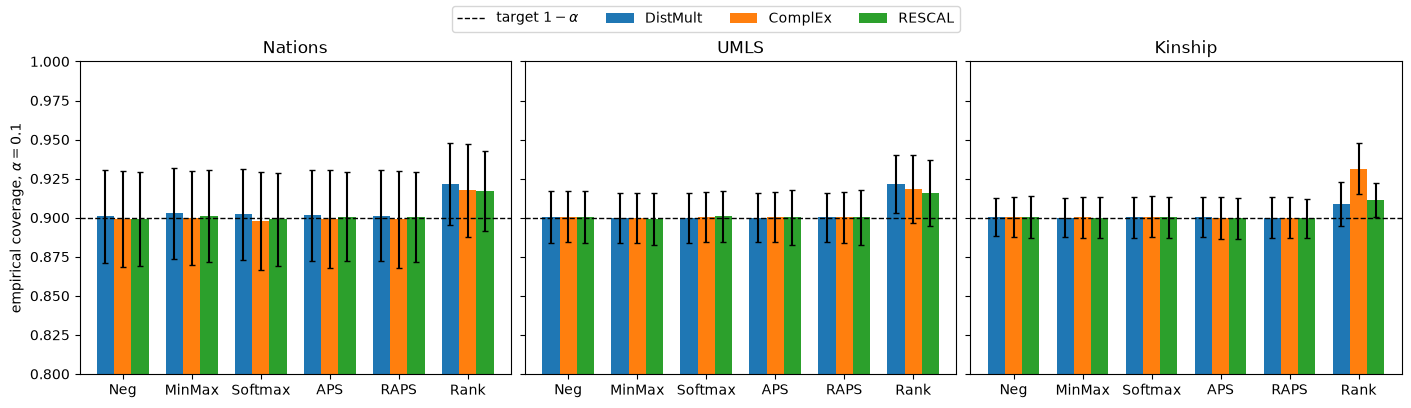

score                       Neg         MinMax        Softmax            APS  \
dataset model                                                                  
Nations DistMult  0.901 ± 0.030  0.903 ± 0.029  0.902 ± 0.029  0.901 ± 0.029   
        ComplEx   0.899 ± 0.031  0.900 ± 0.030  0.898 ± 0.031  0.899 ± 0.031   
        RESCAL    0.899 ± 0.030  0.901 ± 0.029  0.899 ± 0.030  0.901 ± 0.028   
UMLS    DistMult  0.901 ± 0.017  0.900 ± 0.016  0.900 ± 0.016  0.900 ± 0.016   
        ComplEx   0.900 ± 0.016  0.900 ± 0.016  0.901 ± 0.016  0.900 ± 0.016   
        RESCAL    0.901 ± 0.017  0.899 ± 0.017  0.901 ± 0.016  0.900 ± 0.017   
Kinship DistMult  0.900 ± 0.012  0.900 ± 0.012  0.900 ± 0.013  0.900 ± 0.013   
        ComplEx   0.900 ± 0.013  0.900 ± 0.013  0.901 ± 0.013  0.900 ± 0.014   
        RESCAL    0.900 ± 0.013  0.900 ± 0.013  0.900 ± 0.013  0.900 ± 0.013   

score                      RAPS           Rank  
dataset model                                   
Nations DistMult  0.901 ± 0.029  0.922 ± 0.026  
        ComplEx   0.899 ± 0.031  0.917 ± 0.030  
        RESCAL    0.901 ± 0.029  0.917 ± 0.026  
UMLS    DistMult  0.900 ± 0.016  0.922 ± 0.018  
        ComplEx   0.900 ± 0.016  0.918 ± 0.022  
        RESCAL    0.900 ± 0.018  0.916 ± 0.021  
Kinship DistMult  0.900 ± 0.013  0.909 ± 0.014  
        ComplEx   0.900 ± 0.013  0.931 ± 0.016  
        RESCAL    0.899 ± 0.013  0.911 ± 0.011

In [3]:
import matplotlib.pyplot as plt


def plot_bars(metric: str, ylabel: str, sharey: bool = True, fmt: str = "{:.3f}"):
    """Mean ± std of a metric over the 5 seeds × 100 splits: a panel per dataset, a group
    of bars per score, a bar per model. Returns the figure and a table of mean ± std."""
    stats = results.groupby(["dataset", "model", "score"])[metric].agg(["mean", "std"])
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(14, 4), sharey=sharey, layout="constrained")
    for ax, dataset in zip(axes, DATASETS, strict=True):
        panel = stats.loc[dataset].unstack("model").loc[list(SCORES)]  # [score, (mean/std, model)]
        panel["mean"][MODELS].plot.bar(
            ax=ax, yerr=panel["std"][MODELS], capsize=2, rot=0, width=0.75, legend=False
        )
        ax.set(title=dataset, xlabel="")
    axes[0].set_ylabel(ylabel)
    table = stats["mean"].map(fmt.format) + " ± " + stats["std"].map(fmt.format)
    rows = pd.MultiIndex.from_product([DATASETS, MODELS])
    return fig, table.unstack("score").loc[rows, list(SCORES)]


fig, table = plot_bars("coverage", r"empirical coverage, $\alpha = 0.1$")
for ax in fig.axes:
    ax.axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1, label=r"target $1 - \alpha$")
    ax.set_ylim(0.8, 1)
fig.legend(*fig.axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=4)
plt.show()
table

With all scores but Rank, the 45 means are within 0.003 of the target, whatever the model and dataset. The error bars match the expected spread in the table above, and shrink as the test set grows: ± 0.03 on Nations, ± 0.013 on Kinship. They come from the random splits rather than the training seeds, since the standard deviation within one seed is about as large. The guarantee holds on average: single splits of Nations covered between 77% and 99% of their queries.

Rank over-covers, 0.91 to 0.93. The guarantee is a lower bound, so it still holds, but the sets are the top $k$ candidates for a whole number $k$: their coverage jumps past 0.9 from one $k$ to the next, and many calibration queries tie at the threshold rank.

## Average set size

Coverage alone is easy: the set of all candidates covers every query. What makes a conformal predictor useful is a **small set at the guaranteed coverage**. The guarantee holds for any score and any model, but the set size does not: it measures how well the score ranks the true answer among the candidates.

We measure it on the same prediction sets as the coverage above: same models, scores, splits and thresholds $\hat q$. Each bar below is the size that buys the coverage of the corresponding bar above, so with coverage at 0.9 everywhere (Rank aside), sizes can be compared directly across scores and models.

- **Set size** of a test query: the number of candidates in its set, from 0 (empty set) to its number of candidates. Known answers from train and valid are filtered out, so they never count.
- **Mean set size** of a split: the average over its $m$ test queries (201 on Nations, 661 on UMLS, 1074 on Kinship).
- **Repetitions:** as above, 500 values per bar (5 seeds × 100 splits): the bar is their mean, the error bar ± 1 standard deviation.

The datasets have different numbers of entities, so the panels below have their own y-axis. The number of candidates per test query, after filtering, is the same for every model:

| Dataset | Entities | Candidates per query: mean | min–max |
|---|---|---|---|
| Nations | 14 | 8.7 | 2–14 |
| UMLS | 135 | 117.9 | 12–135 |
| Kinship | 104 | 95.4 | 78–104 |

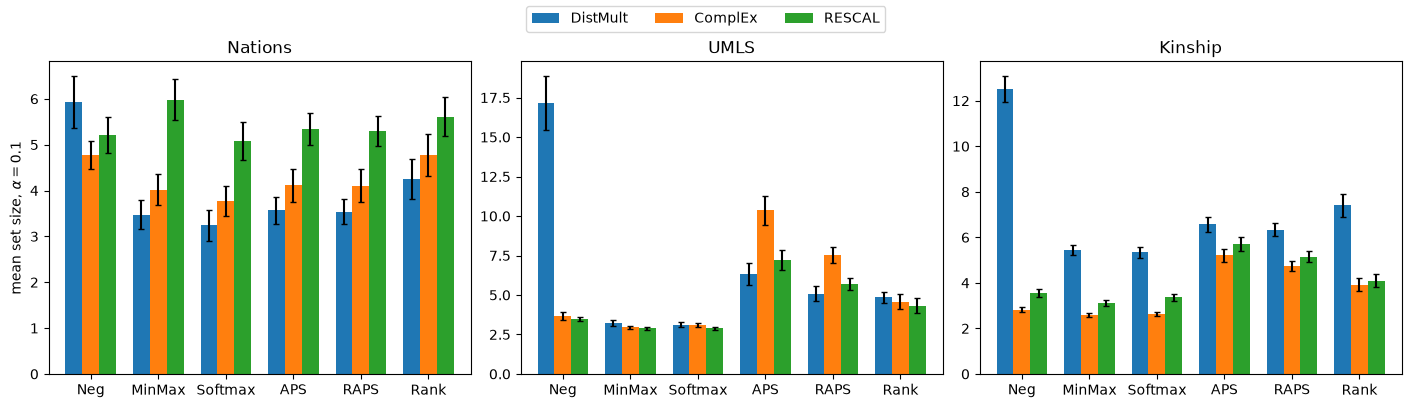

score                      Neg       MinMax      Softmax           APS  \
dataset model                                                            
Nations DistMult   5.93 ± 0.56  3.48 ± 0.31  3.24 ± 0.33   3.57 ± 0.30   
        ComplEx    4.78 ± 0.30  4.02 ± 0.33  3.77 ± 0.34   4.11 ± 0.36   
        RESCAL     5.21 ± 0.39  5.98 ± 0.45  5.08 ± 0.42   5.34 ± 0.34   
UMLS    DistMult  17.16 ± 1.68  3.22 ± 0.20  3.12 ± 0.17   6.32 ± 0.68   
        ComplEx    3.64 ± 0.26  2.94 ± 0.10  3.10 ± 0.11  10.36 ± 0.90   
        RESCAL     3.49 ± 0.13  2.89 ± 0.08  2.88 ± 0.08   7.20 ± 0.64   
Kinship DistMult  12.52 ± 0.56  5.43 ± 0.22  5.34 ± 0.24   6.57 ± 0.33   
        ComplEx    2.82 ± 0.12  2.58 ± 0.09  2.64 ± 0.10   5.21 ± 0.28   
        RESCAL     3.56 ± 0.19  3.12 ± 0.13  3.37 ± 0.15   5.71 ± 0.32   

score                    RAPS         Rank  
dataset model                               
Nations DistMult  3.53 ± 0.27  4.25 ± 0.43  
        ComplEx   4.11 ± 0.36  4.77 ± 0.46  
        RESCAL    5.30 ± 0.34  5.61 ± 0.43  
UMLS    DistMult  5.09 ± 0.45  4.86 ± 0.36  
        ComplEx   7.54 ± 0.52  4.58 ± 0.49  
        RESCAL    5.71 ± 0.38  4.32 ± 0.47  
Kinship DistMult  6.34 ± 0.30  7.40 ± 0.51  
        ComplEx   4.75 ± 0.21  3.92 ± 0.28  
        RESCAL    5.14 ± 0.25  4.09 ± 0.29

In [4]:
fig, table = plot_bars("size", r"mean set size, $\alpha = 0.1$", sharey=False, fmt="{:.2f}")
fig.legend(*fig.axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=3)
plt.show()
table

At the same coverage, the sets differ a lot in size, and the score matters as much as the model:

- **Softmax and MinMax give the smallest sets** for every model, within 8% of each other except on Nations RESCAL (MinMax 18% larger). On UMLS, a set holds about 3 of the 118 candidates of a query, on Kinship 2.6 to 5.3 of 95. Nations has only 8.7 candidates per query, and the sets keep 3.2 to 5.1 of them.
- **Neg** needs logits that are comparable across queries. DistMult uses reciprocal relations: head queries are scored with a separate inverse relation, on another scale than tail queries, and one threshold on raw logits cannot suit both. Its Neg sets are 1.8 to 5.5 times larger than Softmax's, up to 17 entities on UMLS.
- **APS** sets are 2.0 to 3.3 times larger than Softmax's on UMLS, 1.2 to 2.0 times on Kinship. APS adds up probability mass until the true answer is included, so flat probabilities need many candidates: the factor is largest for the models trained with label smoothing (ComplEx on UMLS and Kinship, RESCAL on Kinship). RAPS penalizes ranks beyond 5 and cuts these sets by 19 to 27% on UMLS.
- **Rank** sets are 1.1 to 1.6 times larger than Softmax's: every query gets the same top $k$, easy queries included, and part of the size buys the over-coverage seen above.

**Models.** With Softmax, a more accurate model gives smaller sets: on Kinship, ComplEx (test MRR 0.882) halves the sets of DistMult (0.704), 2.64 against 5.34 entities, and on Nations the sets grow from DistMult to ComplEx to RESCAL as MRR drops. But the order of the models depends on the score: on UMLS, ComplEx has the smallest MinMax sets and the largest APS sets. Models are best compared with the same score. See [set size and model accuracy](../docs/conformal_prediction.md#set-size-and-model-accuracy) for set size next to MRR and Hits@k.

**Error bars.** Unlike coverage, the size depends on the trained model, so the 500 values vary with both the split and the seed. For Softmax and MinMax, the splits account for most of the spread (DistMult on UMLS aside); for APS on UMLS, the seeds vary as much as the splits or more.

**Next:** [02_benchmarks](02_benchmarks.ipynb) uses the same protocol on the four standard benchmarks, WN18, FB15k, WN18RR and FB15k-237, with the KGE models published by LibKGE's authors, and explains why the sets get so large on the harder versions.